# 04 · Detection pipeline

The keypoint network expects a single, loosely framed face. This notebook runs it on arbitrary photos:

1. **Detect faces** with OpenCV's pre-trained Haar cascade (`detector_architectures/`).
2. **Crop each face with a margin** (`pad`) so that it is framed the way the training images were, then convert it to grayscale and resize it to 224×224.
3. **Predict the 68 keypoints** with v2 and map them back to the original image.

Steps 1–3 are in `pipeline.py`. The margin is calibrated on the training split, and its effect is measured on the validation split. The holdout is not used here.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import metrics
from data_load import read_rgb, split_by_identity
from models import load_trained
from pipeline import DEFAULT_PAD, crop_face, detect_faces, load_rgb, overlay_sunglasses, predict_keypoints

net = load_trained(config.FINAL_WEIGHTS)
print("model:", config.FINAL_WEIGHTS.name, "| device:", config.DEVICE)

model: keypoints_cnn_v2.pt | device: mps


## 1. Face detection

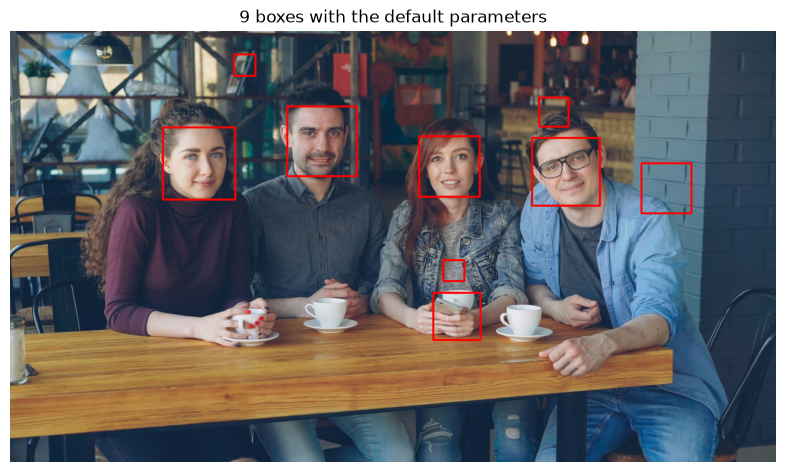

In [2]:
group = load_rgb(config.IMAGES_DIR / "group_cafe.jpg")  # photo: Vitaly Gariev, Unsplash License
faces = detect_faces(group)

shown = group.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(shown, (x, y), (x + w, y + h), (255, 0, 0), 4)
plt.figure(figsize=(10, 5.6)); plt.imshow(shown); plt.axis("off")
plt.title(f"{len(faces)} boxes with the default parameters"); plt.show()

Haar cascades are fast but crude. With the original parameters (`scaleFactor=1.2`, `minNeighbors=2`) they find the four faces, but they also fire on background patterns and on the hands. A minimum box size, as a fraction of the image's shorter side, filters them:

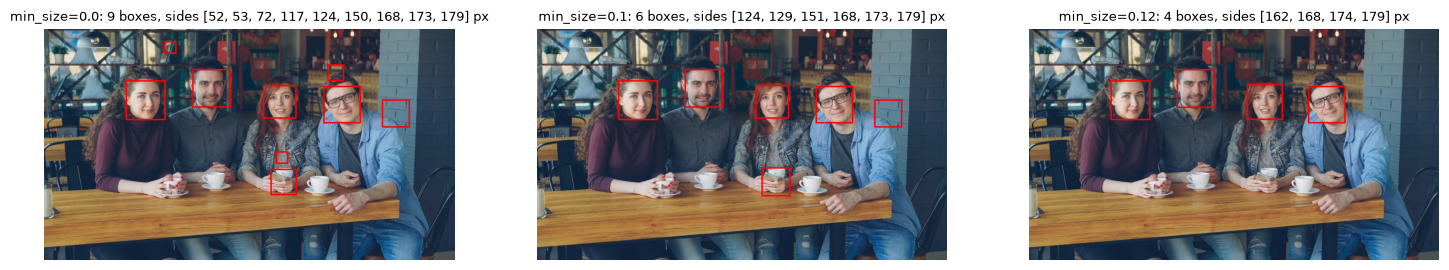

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.6))
for ax, min_size in zip(axes, [0.0, 0.1, 0.12]):
    boxes = detect_faces(group, min_size=min_size)
    shown = group.copy()
    for (x, y, w, h) in boxes:
        cv2.rectangle(shown, (x, y), (x + w, y + h), (255, 0, 0), 6)
    ax.imshow(shown); ax.axis("off")
    ax.set_title(f"min_size={min_size}: {len(boxes)} boxes, sides {sorted(int(b[2]) for b in boxes)} px", fontsize=9)
plt.show()

MIN_SIZE = 0.12
faces = sorted(detect_faces(group, min_size=MIN_SIZE), key=lambda b: b[0])  # left to right

Without a size filter, the cascade returns 9 boxes: the four faces (150–179 px) and five false positives (52–124 px) on the background, the brick wall and the hands holding a phone. `min_size=0.1` removes the three smallest, but two remain: the wall (124 px) and the hands (129 px). At `min_size=0.12`, about 128 px for this 1069 px-tall photo, only the four faces are left; the scan itself also starts at a larger window, which is why the 124 px box disappears too. The gap between the smallest face and the largest false positive is small, so this threshold is specific to the photo: a crowd photo with distant faces would need a lower one.

## 2. Why the crop needs a margin

The training images are loose crops: forehead, ears and chin are all visible, and the network sees the central 224/250 of the shorter side. A Haar box is much tighter: it runs roughly from the forehead to the chin, with little around it. Feeding the raw box makes the face look almost twice as large as anything the network was trained on.

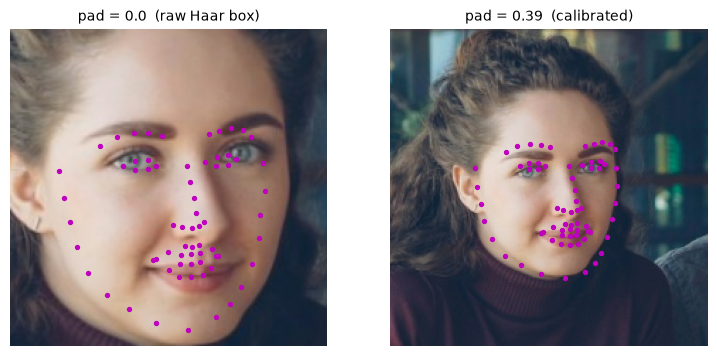

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
box = faces[0]
for ax, pad in zip(axes, [0.0, DEFAULT_PAD]):
    crop, origin, scale = crop_face(group, box, pad)
    pts = predict_keypoints(net, group, [box], pad)[0]
    ax.imshow(crop)
    ax.scatter(*((pts - origin) / scale).T, s=8, c="m")
    ax.set_title(f"pad = {pad}" + ("  (raw Haar box)" if pad == 0 else "  (calibrated)"), fontsize=10)
    ax.axis("off")
plt.show()

### Calibrating the margin on the training split

On each training image where the cascade finds exactly one face, the margin is the one that turns the Haar box into the region the network saw during training: `(224/250 · shorter side / box side − 1) / 2`. The calibrated value is the median.

In [5]:
train_df, val_df, _ = split_by_identity(pd.read_csv(config.TRAIN_CSV), config.SPLIT_FRACTIONS, config.SPLIT_SEED)

pads, counts = [], []
for name in train_df.iloc[:, 0]:
    image = read_rgb(config.TRAIN_DIR / name)
    boxes = detect_faces(image)
    counts.append(len(boxes))
    if len(boxes) == 1:
        side = max(boxes[0][2:])
        pads.append((config.IMAGE_SIZE / config.RESCALE_SIZE * min(image.shape[:2]) / side - 1) / 2)
counts = np.array(counts)
print(f"Haar on train images: 0 faces {100 * (counts == 0).mean():.1f}%, exactly one {100 * (counts == 1).mean():.1f}%, "
      f"more {100 * (counts > 1).mean():.1f}%")
print(f"calibrated pad: median {np.median(pads):.2f} (IQR {np.percentile(pads, 25):.2f}–{np.percentile(pads, 75):.2f}); "
      f"pipeline.DEFAULT_PAD = {DEFAULT_PAD}")

Haar on train images: 0 faces 1.0%, exactly one 93.8%, more 5.1%
calibrated pad: median 0.39 (IQR 0.32–0.48); pipeline.DEFAULT_PAD = 0.39


### Before / after on the validation split

Each validation image is run through the full pipeline: Haar detection (largest box), a padded crop and v2. The predictions are compared with the ground truth for several margins. The dataset's own framing (`Rescale` + `CenterCrop`, the setting used in notebook 03) is shown as a reference.

In [6]:
gt_val = metrics.ground_truth(val_df)
images = [read_rgb(config.TRAIN_DIR / n) for n in val_df.iloc[:, 0]]
boxes = [detect_faces(im) for im in images]
found = np.array([len(b) > 0 for b in boxes])
largest = [max(b, key=lambda r: r[2] * r[3]) for b in boxes if len(b)]
print(f"faces found in {found.sum()} of {len(found)} validation images")

pad_grid = [0.0, 0.1, 0.2, 0.3, DEFAULT_PAD, 0.5, 0.6, 0.7]
sweep = {}
for pad in pad_grid:
    preds = np.stack([predict_keypoints(net, im, [b], pad)[0]
                      for im, b in zip([im for im, f in zip(images, found) if f], largest)])
    sweep[pad] = metrics.summary(preds, gt_val[found])
dataset_framing = metrics.summary(metrics.predict_frame(net, val_df[found], config.TRAIN_DIR), gt_val[found])

table = pd.DataFrame(sweep).T
table.index.name = "pad"
table.loc["dataset framing"] = dataset_framing
table.round(2)

faces found in 528 of 528 validation images


,mean_px,median_px,nme_%,median_nme_%,failure_rate_%(nme>0.10)
pad,,,,,
0.0,8.87,7.32,18.32,16.86,88.64
0.1,6.17,4.77,12.73,10.97,57.58
0.2,5.00,3.90,10.40,8.82,39.77
0.3,4.64,3.74,9.74,8.16,31.63
0.39,4.69,3.75,9.88,8.54,32.58
0.5,5.04,4.11,10.66,9.37,40.91
0.6,5.66,4.68,11.85,10.55,54.73
0.7,6.46,5.37,13.46,11.96,67.05
dataset framing,5.18,4.28,11.52,9.44,43.75


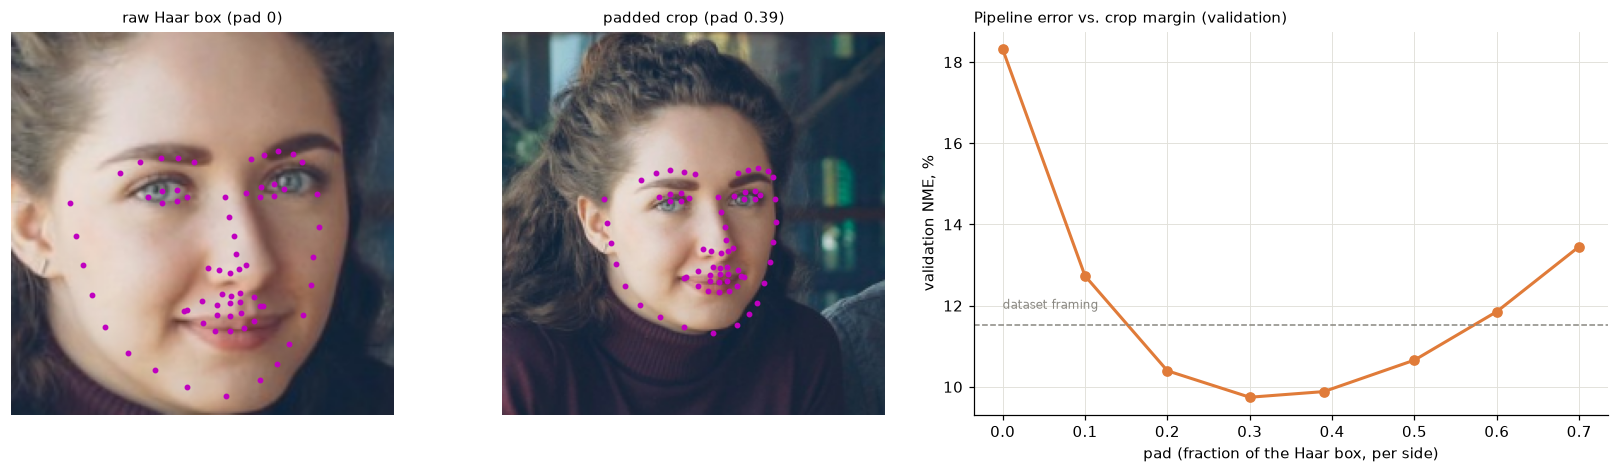

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), dpi=110, gridspec_kw={"width_ratios": [1, 1, 1.5]})
for ax, pad in zip(axes[:2], [0.0, DEFAULT_PAD]):
    crop, origin, scale = crop_face(group, faces[0], pad)
    pts = predict_keypoints(net, group, [faces[0]], pad)[0]
    ax.imshow(crop); ax.scatter(*((pts - origin) / scale).T, s=8, c="m"); ax.axis("off")
    ax.set_title("raw Haar box (pad 0)" if pad == 0 else f"padded crop (pad {pad})", fontsize=10)
ax = axes[2]
nmes = [sweep[p]["nme_%"] for p in pad_grid]
ax.plot(pad_grid, nmes, marker="o", color="#e07b39", linewidth=2)
ax.axhline(dataset_framing["nme_%"], color="#898781", linestyle="--", linewidth=1)
ax.text(0.0, dataset_framing["nme_%"] + 0.4, "dataset framing", color="#898781", fontsize=8)
ax.set_xlabel("pad (fraction of the Haar box, per side)")
ax.set_ylabel("validation NME, %")
ax.set_title("Pipeline error vs. crop margin (validation)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e1e0d9", linewidth=0.6)
fig.tight_layout()
fig.savefig(config.ASSETS_DIR / "padding_comparison.png", bbox_inches="tight")
plt.show()

**The margin matters a lot.**
- **The raw Haar box doubles the error.** Validation NME goes from 9.9 % with the calibrated margin to 18.3 % without one. On the raw box the face fills the crop, much larger than any training face, and the predicted shape is too small for it: the jaw contour falls on the cheeks instead of the face outline.
- **The calibrated value sits near the best margin.** It was set from training-image statistics, not tuned on validation. The error curve is flat between 0.3 and 0.4: 0.3 scores 9.7 % and the calibrated 0.39 scores 9.9 %.
- **The full pipeline beats the dataset's own framing** (9.9 % against 11.5 %). The detector centers each face in its crop, which removes the off-center, small-face failures seen in notebook 03.

## 3. Full pipeline

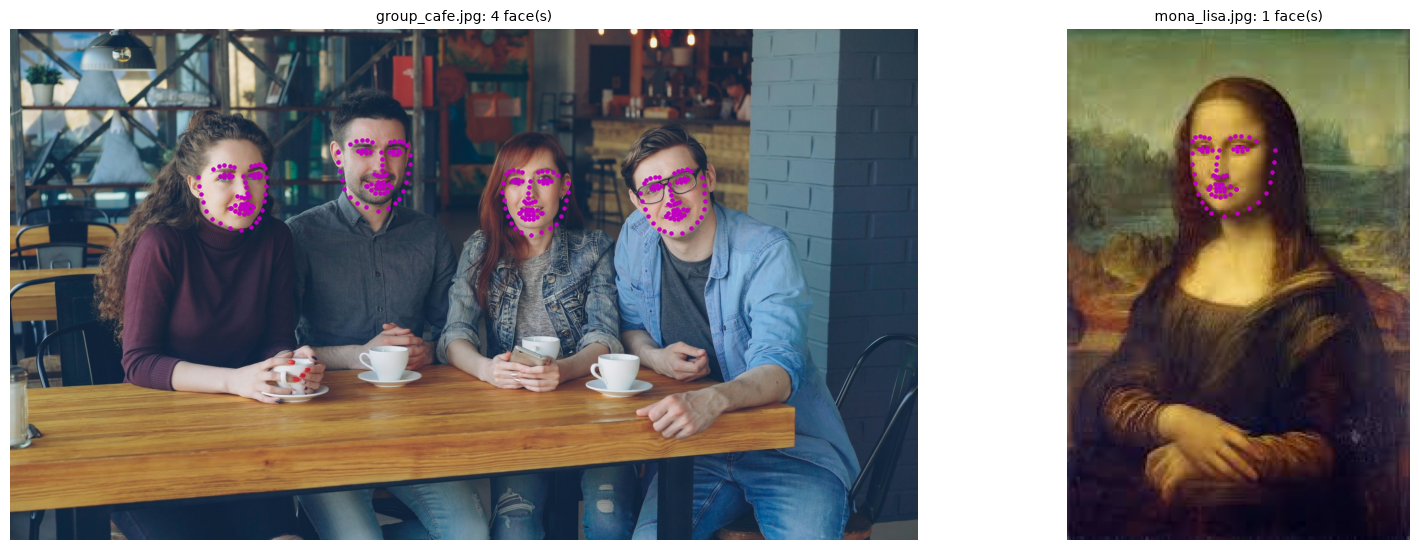

In [8]:
def run_pipeline(path, min_size=MIN_SIZE):
    image = load_rgb(path)
    boxes = detect_faces(image, min_size=min_size)
    return image, boxes, predict_keypoints(net, image, boxes)


fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.78, 0.67]})
for ax, name in zip(axes, ["group_cafe.jpg", "mona_lisa.jpg"]):
    image, boxes, keypoints = run_pipeline(config.IMAGES_DIR / name)
    ax.imshow(image)
    for pts in keypoints:
        ax.scatter(*pts.T, s=5, c="m")
    ax.set_title(f"{name}: {len(boxes)} face(s)", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(config.ASSETS_DIR / "pipeline_examples.png", bbox_inches="tight", dpi=100)
plt.show()

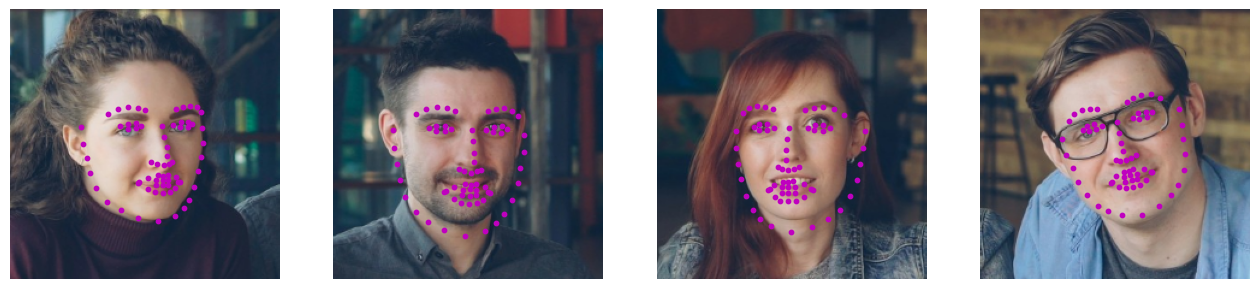

In [9]:
# Close-ups: keypoints on each detected face
image, boxes, keypoints = run_pipeline(config.IMAGES_DIR / "group_cafe.jpg")
fig, axes = plt.subplots(1, len(boxes), figsize=(4 * len(boxes), 4))
for ax, box, pts in zip(np.atleast_1d(axes), sorted(boxes, key=lambda b: b[0]),
                        [p for _, p in sorted(zip([b[0] for b in boxes], keypoints), key=lambda t: t[0])]):
    crop, origin, scale = crop_face(image, box)
    ax.imshow(crop); ax.scatter(*((pts - origin) / scale).T, s=10, c="m"); ax.axis("off")
plt.show()

**On real photos.** The predicted shapes follow all four faces in the group photo and the Mona Lisa. Eyes, nose and mouth sit in the right places on the two frontal faces in the middle. The two people on the sides tilt their heads, and their shapes follow the tilt only partially: on the right, the eye line is less tilted than the real one and the mouth points drift slightly toward the cheek. This is the frontal bias seen on the holdout in notebook 03.

**Limitations of this pipeline.**
- The Haar cascade only finds roughly frontal faces. Profiles and strongly tilted heads are missed before the keypoint model ever sees them.
- `min_size` has to suit the photo: here, the false positives on the wall and the hands are only slightly smaller than the faces.
- A margin calibrated for this dataset assumes faces framed like YouTube Faces crops. A modern CNN face detector (for example OpenCV's DNN module or RetinaFace) would fix the first two points.